# 03 — Annotation Audit, Chemical Class Enrichment & Endogenous Com20 Metabolism (Step 5)

**Course tools integrated:** Weeks 6–7 (Over-Representation / Enrichment Analysis with BH-FDR), Week 8 (LC-MS/MS Annotation Confidence & Dark Metabolome), Week 13 (Chemical Ontologies & Curated Knowledge Bases via RDKit SMARTS).

Only **259 / 3,414 filtered features (7.6%)** have MS2 spectral-library or lipid annotations—a classic reminder of the metabolomics "dark matter" constraint. Before running enrichment analysis, we systematically **audit** all 259 annotations to separate genuine biology from technical artifacts:
- **Study carryover drugs (10 of the other 11 drugs from Pakkir Shah et al.):** `Erythromycin`/`Clarithromycin`, `Metronidazole`, `Ketoconazole`, `Sertraline`, `Simvastatin`, `Loratadine`, `Clomifene`/`Enclomiphene`, `Montelukast`, `Telmisartan`, and `Lansoprazole` appear at trace carryover levels from the multi-drug LC-MS batch.
- **QC-Mix standards:** `Sulfamethizole`, `Sulfachloropyridazine`, `Sulfadimethoxine`, `Sulfisomidine`, `Trimethoprim`, `Amitriptyline`.
- **False-positive library match caught by isotope physics:** `ID 5664` (`m/z 441.1858`, Omeprazole-specific, increasing strongly T0→T8) is matched by MS2 cosine to chlorinated `Sertindole` (`C24H26ClFN4O`), yet completely lacks the mandatory **32% `³⁷Cl` M+2 isotope peak** at `443.1828`—proving it is a false library hit on a real unannotated omeprazole derivative.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

PROC = ROOT / "data" / "processed"
TABLES = ROOT / "results" / "tables"
FIGS = ROOT / "results" / "figures"

ann_cur = pd.read_csv(PROC / "feature_annotations_curated.csv", index_col=0)
ora = pd.read_csv(TABLES / "table05_chemical_class_enrichment.csv")
endo_hits = pd.read_csv(TABLES / "table04_top_endogenous_hits.csv", index_col="row_id")

print("=== Curated Annotation Class Breakdown (259 filtered annotated features) ===")
display(ann_cur.groupby(["origin_category", "chemical_class"]).size().reset_index(name="n_features").sort_values(["origin_category", "n_features"], ascending=[True, False]))

=== Curated Annotation Class Breakdown (259 filtered annotated features) ===


,origin_category,chemical_class,n_features
3,Endogenous/Medium,"Fatty Acids, Oxylipins & Lipids",66
2,Endogenous/Medium,Cyclic Dipeptides (DKPs),37
5,Endogenous/Medium,N-Acyl Amino Acids,19
0,Endogenous/Medium,Amino Acids & Linear Peptides,17
7,Endogenous/Medium,Other Annotated Metabolites,17
4,Endogenous/Medium,Indoles & Tryptophan Derivatives,16
8,Endogenous/Medium,Plant Polyphenols & Isoflavones (mGAM),14
6,Endogenous/Medium,"Nucleosides, Purines & Amines",13
1,Endogenous/Medium,Bile Acids,5
9,Omeprazole-derived,Omeprazole & Benzimidazole Derivatives,12


## Chemical Class Over-Representation Analysis (Fisher's Exact Test, BH-FDR)

Using all non-carryover biological/drug annotations (`n = 228`) as the measured background (matching Week 7 best practices—never testing against the entire universe of unmeasured compounds!):

1. **Omeprazole-Enriched Features (`q < 0.05, log₂FC > 1`):** Dominated exclusively by **Omeprazole & Benzimidazole Derivatives (`11/12`, `10.1×` enrichment, `q = 2.16 × 10⁻¹¹`)**.
2. **Com20 Time-Increasing Features (Active Bacterial Production, T0→T8):** Significantly enriched for **Bile Acids (`4/5`, `5.5×`, `q = 0.012`)** (bacterial bile salt hydrolase deconjugation of mGAM bile salts -> `Cholic acid`) and **N-Acyl Amino Acids (`8/19`, `2.9×`, `q = 0.012`)** (gut microbial synthesis of `Gly-C17:1`, `3-OH-C17-Gly`, `Phe-C4:0`, `Phe-C6:0`).
3. **Stable mGAM Medium Background (`det_medium ≥ 2, |β_time| < 0.08`):** Overwhelmingly enriched for **Cyclic Dipeptides / Diketopiperazines (`32/37`, `3.7×`, `q = 1.06 × 10⁻¹⁸`)**—high-abundance peptone/autoclave medium constituents (`Cyclo(Pro-Leu)`, `Cyclo(Phe-Pro)`) that remain constant across growth.
4. **Endogenous Com20 Perturbations Under Omeprazole (strictly outside the `RT 1.80–2.25 min` ion-suppression window):**
   - Most core pathways (e.g., `N-Acetylhistamine` >100× production, `Gly-C17:1` synthesis, `Oleic acid` depletion) are **highly conserved** between DMSO and Omeprazole.
   - However, selective endogenous pathways show reproducible attenuation/delay under omeprazole: **`Indole-3-propionic acid` (`ID 4553, RT 2.60 min, GNPS score 0.974`)** shows ~2-fold lower late accumulation (`3.2×10⁵` in DMSO vs `1.6×10⁵` in Omeprazole, `q_trt = 0.0012`), and bacterial membrane phospholipid **`PE 13:0` (`ID 7477, RT 3.97 min`)** is delayed until T7–T8 (`q_int = 0.012`).

=== Chemical Class Enrichment Results (p < 0.15) ===


,Hit_Set,Chemical_Class,Hits_in_Class,Total_in_Class,Fold_Enrichment,p_value,q_value,Example_Compounds
0,Com20 Time-Decreasing (Bacterial Uptake/Deplet...,"Fatty Acids, Oxylipins & Lipids",22,66,1.46,1.441250e-02,1.585374e-01,NAE 16:4; Spectral Match to 9(10)-EpOME from N...
1,Com20 Time-Decreasing (Bacterial Uptake/Deplet...,N-Acyl Amino Acids,8,19,1.84,4.138909e-02,2.276400e-01,Gly-C18:1; Oleyl sarcosine; Candidate 2-aminov...
2,Com20 Time-Decreasing (Bacterial Uptake/Deplet...,Amino Acids & Linear Peptides,7,17,1.80,6.384558e-02,2.341005e-01,Spectral Match to Leu-Val from NIST14; Spectra...
11,Com20 Time-Increasing (Bacterial Production),Bile Acids,4,5,5.46,1.764032e-03,1.217533e-02,Spectral Match to Cholic acid from NIST14; Spe...
12,Com20 Time-Increasing (Bacterial Production),N-Acyl Amino Acids,8,19,2.87,2.213696e-03,1.217533e-02,Candidate Histamine-C5:0 (delta mass:84.0578);...
13,Com20 Time-Increasing (Bacterial Production),Plant Polyphenols & Isoflavones (mGAM),5,14,2.44,3.771632e-02,1.382932e-01,Daidzein; Glycitein; naringenin CollisionEnerg...
22,"Omeprazole-Enriched (q<0.05, log2FC>1)",Omeprazole & Benzimidazole Derivatives,11,12,10.13,1.965818e-12,2.162400e-11,Omeprazole 4-desmethylthioether; 37052-78-1; o...
33,Stable mGAM Medium Background,Cyclic Dipeptides (DKPs),32,37,3.72,9.605534e-20,1.056609e-18,Cyclo-prolylglycine; NCGC00380778-01_C9H14N2O3...


=== Top Clean Endogenous Metabolites (Outside RT 1.80-2.25 Suppression Window) ===


,mz,rt,chemical_class,compound_name,score,beta_time,q_time,beta_trt,q_trt,beta_int,q_int
row_id,,,,,,,,,,,
232,181.097183,0.243494,Cyclic Dipeptides (DKPs),"1,6-propano-3-ethylideno-1,4-piperazine-2,5-dione",0.755,-0.036051,6.749008e-01,4.540525,2.705136e-34,0.078446,0.215464
616,168.101971,0.370168,"Fatty Acids, Oxylipins & Lipids",SPB 9:4;O2,0.609,-0.158207,4.137028e-01,6.148452,1.768819e-19,0.384568,0.039561
9644,344.279598,5.052988,N-Acyl Amino Acids,Putative (3-hydroxyheptadecanoyl)glycine,0.710,0.492001,4.367558e-19,-0.113766,3.351726e-01,-0.040609,0.486890
167,154.097554,0.226008,"Nucleosides, Purines & Amines",N-Acetylhistamine,0.785,0.879832,1.670892e-17,-0.094022,7.247238e-01,-0.071009,0.561071
9646,326.268846,5.051504,N-Acyl Amino Acids,Gly-C17:1,0.892,0.499002,1.670892e-17,-0.168428,2.000513e-01,-0.029603,0.693808
4191,236.128153,2.441822,N-Acyl Amino Acids,Candidate Phenylalanine-C4:0 (delta mass:70.0409),0.929,0.617686,1.810701e-17,-0.156810,3.529184e-01,-0.026697,0.786264
1040,180.102032,0.587333,Amino Acids & Linear Peptides,Phenylalanine methyl ester,0.962,0.016534,9.868459e-01,2.247102,8.430825e-15,0.051567,0.684812
3795,327.158917,2.251693,Plant Polyphenols & Isoflavones (mGAM),"2,3-bis[(4-hydroxy-3-methoxyphenyl)methyl]buta...",0.837,0.089527,1.394641e-14,0.008498,8.021494e-01,-0.013624,0.322718
9751,324.289688,5.102892,"Fatty Acids, Oxylipins & Lipids",Spectral Match to Linoleoyl ethanolamide from ...,0.785,-0.543055,3.519474e-13,0.045144,8.497062e-01,-0.030167,0.800982


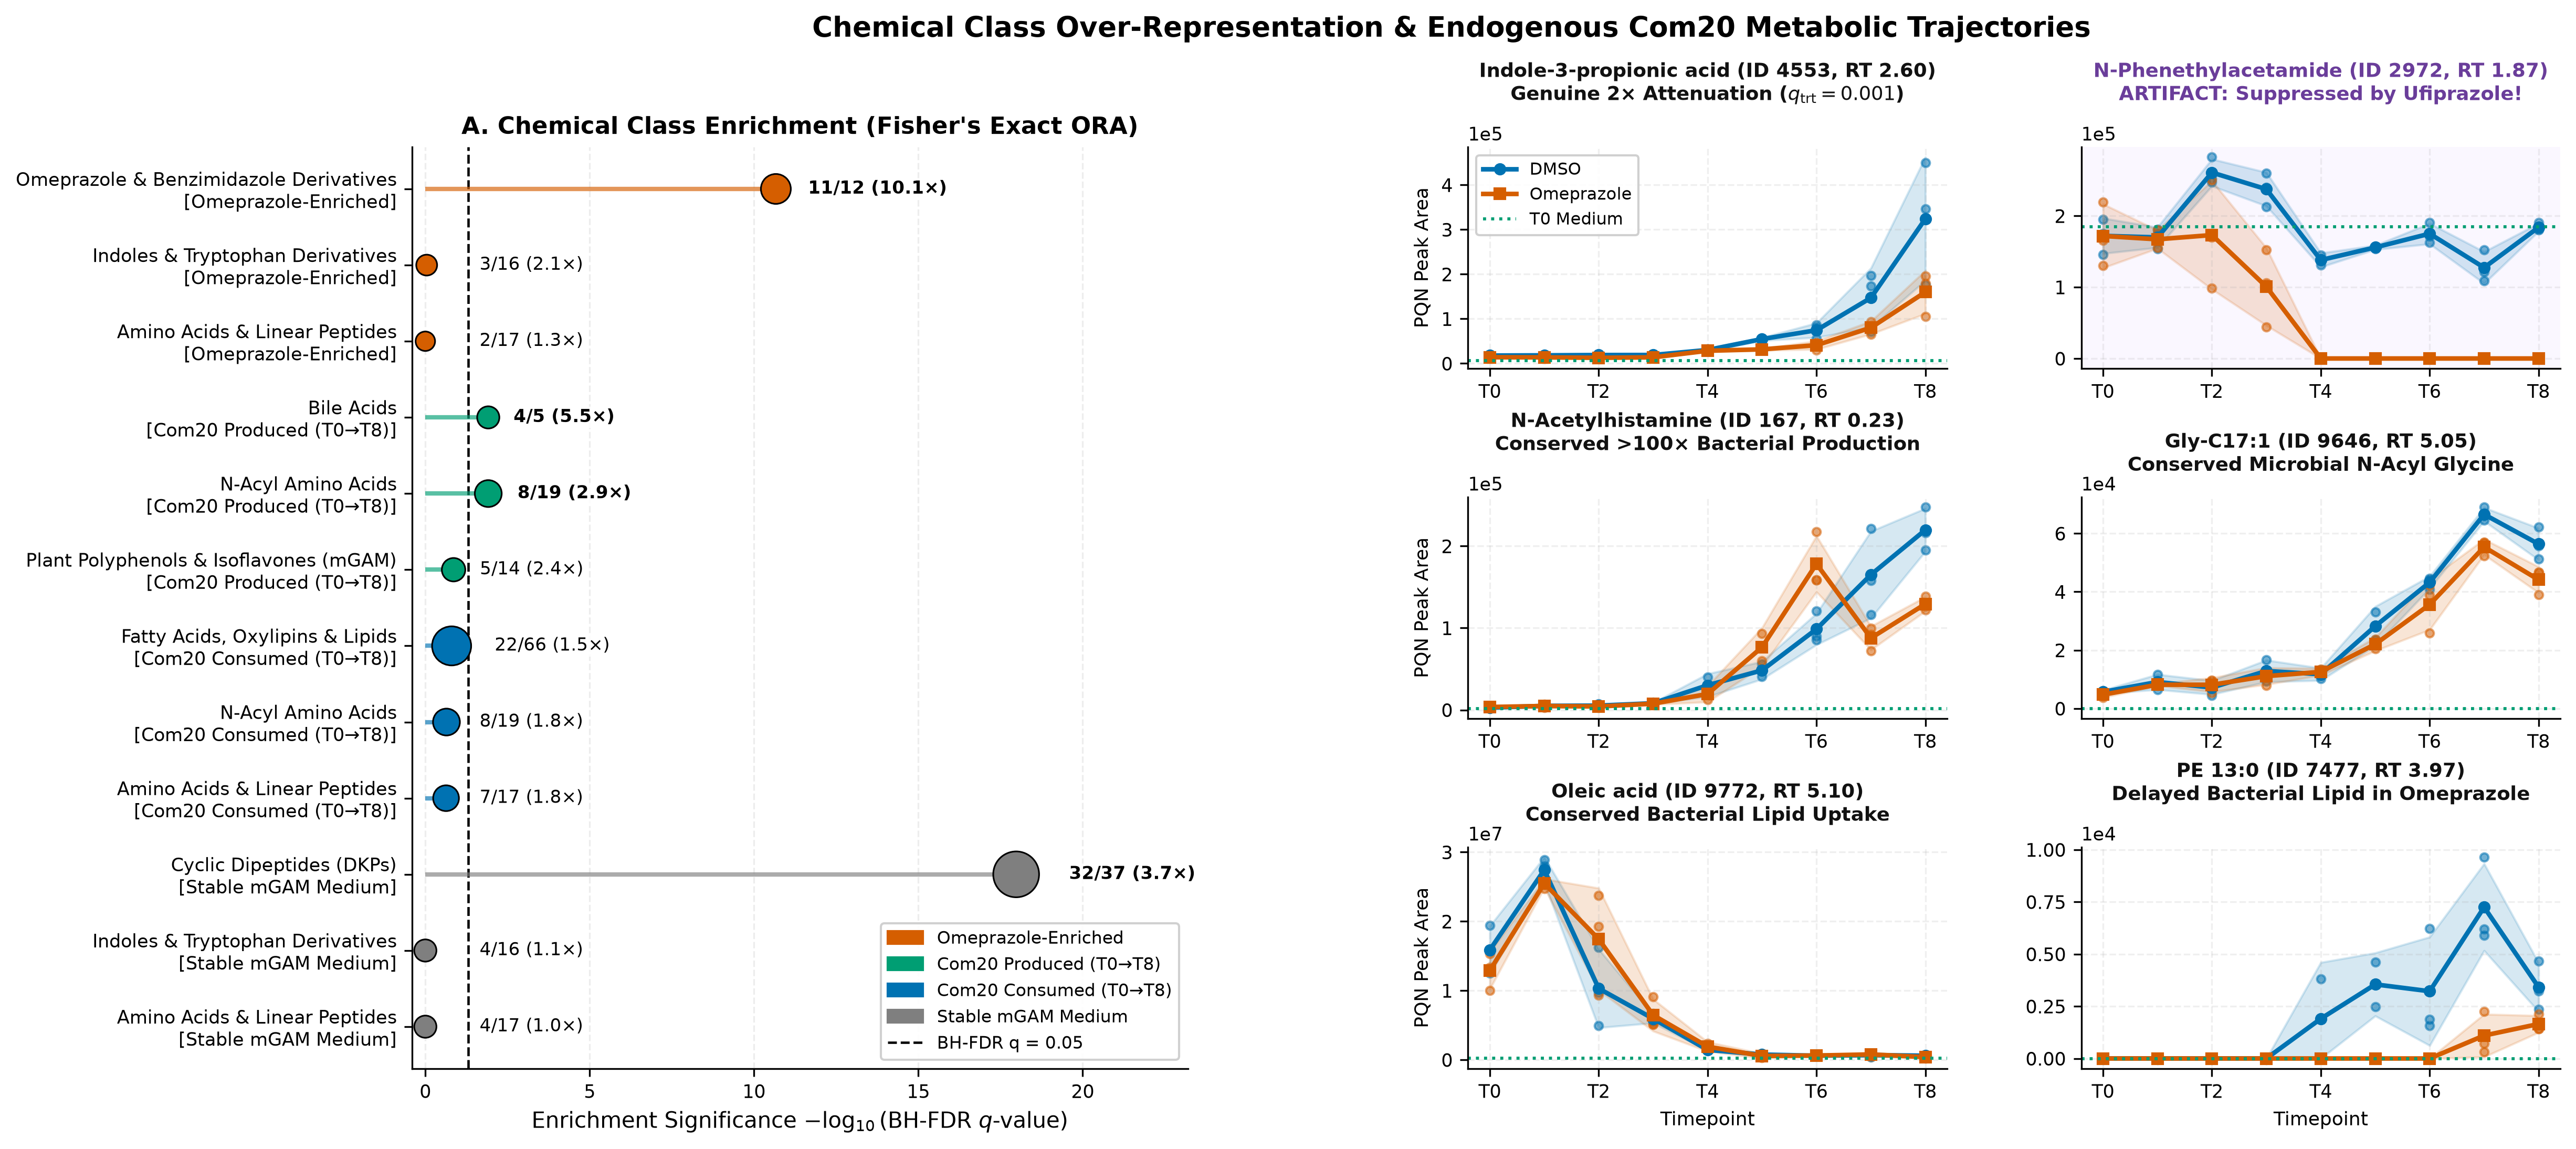

In [2]:
print("=== Chemical Class Enrichment Results (p < 0.15) ===")
display(ora[ora["p_value"] < 0.15][["Hit_Set", "Chemical_Class", "Hits_in_Class", "Total_in_Class", "Fold_Enrichment", "p_value", "q_value", "Example_Compounds"]])

print("=== Top Clean Endogenous Metabolites (Outside RT 1.80-2.25 Suppression Window) ===")
display(endo_hits[["mz", "rt", "chemical_class", "compound_name", "score", "beta_time", "q_time", "beta_trt", "q_trt", "beta_int", "q_int"]].head(20))

display(Image(filename=str(FIGS / "fig07_chemical_class_enrichment_and_endogenous_trajectories.png"), width=1050))